# OISSS SSS per-DBO-box trends — Theil-Sen + AR(1) Mann-Kendall refit

**Why this notebook exists.** The scorecard's sea-surface-salinity row (DBO2 −0.75, DBO3 −0.53
PSU/decade) was fit with **GLS + AR(1)** (`figS04_oisss-sss-box-trends.ipynb`, section 8) —
the **only remaining row** in the scorecard not on the common **Theil-Sen + AR(1)-corrected
Mann-Kendall** estimator (the wind row was converted 2026-08; the σ₀ row was already Theil-Sen).
This notebook refits the *identical* box-mean deseasonalized monthly anomaly series with the common
estimator (ported verbatim from `weekly_pipeline/dbo_weekly/trends.py`) and prints a paste-ready
replacement row for the Fig. 8 scorecard (assembled outside this repository).

**Self-sufficient.** OISSS v3 monthly streams over plain HTTPS from ESR (no Earthdata login).
If the cached stack built by `figS04_oisss-sss-box-trends.ipynb`
(`outputs_longterm_oisss/monthly_sss_ease2_oisss_gauss.nc`) is found, it is reused — **preferred**,
because then the GLS→Theil-Sen comparison is estimator-only (same months, same grid). If no cache
is found the full stack is rebuilt from ESR (~168 fetches, ~15–25 min).

⚠️ If you rebuild rather than reuse the cache, any months published since the last build get
included and the comparison mixes *record extension* with *estimator change*. For the scorecard
update, run on the existing cache first.

## 1. Imports

In [4]:
import warnings, time as _time, io, re, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
from pyresample import AreaDefinition, geometry
from pyresample.kd_tree import resample_nearest, resample_gauss
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


## 2. Configuration — OISSS monthly source, EASE-2 grid, DBO boxes

Identical domain / grid / box definitions to every other DBO product notebook
(`figS04_oisss-sss-box-trends.ipynb` verbatim).

In [5]:
# --- OISSS v3 monthly source (ESR HTTP archive; netCDF-3) ---
OISSS_MONTHLY = "https://oisss.esr.org/data/V3/Monthly"
OISSS_VAR     = "sss"                       # units 1e-3 == PSU numerically

DBO_BBOX  = (-180.0, 50.0, -124.0, 74.0)
RESAMPLE  = "gauss"     # NaN-safe, valid-points-only regrid (matches the cached stack)
ROI       = 30_000      # radius of influence (m); OISSS cells ~25 km
SSS_VALID = (0.0, 45.0)

dbo_area = AreaDefinition(
    area_id="ease2_north_dbo_4km",
    description="EASE-Grid 2.0 North subset: Aleutians -> Beaufort (DBO1-8), 4 km",
    proj_id="EPSG:6931",
    projection={"proj":"laea","lat_0":90,"lon_0":0,"x_0":0,"y_0":0,"datum":"WGS84","units":"m"},
    width=906, height=845, area_extent=(-3_624_000, 992_000, 0, 4_372_000))
xs, ys = dbo_area.get_proj_vectors()

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}

OUT_DIR = Path.cwd() / "outputs_longterm_oisss"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"grid EASE-2 North {dbo_area.shape} | output -> {OUT_DIR}")

grid EASE-2 North (845, 906) | output -> ~/outputs_longterm_oisss


## 3. Load the cached monthly SSS stack (or rebuild it from ESR)

Looks for `monthly_sss_ease2_oisss_gauss.nc` in the usual places. Reusing the cache keeps the
month set identical to the GLS fit, so the comparison below isolates the estimator.

In [6]:
CACHE_NAME = f"monthly_sss_ease2_oisss_{RESAMPLE}.nc"
_search_dirs = [Path.cwd() / "outputs_longterm_oisss",
                Path.cwd() / "salinity" / "outputs_longterm_oisss",
                Path.cwd().parent / "salinity" / "outputs_longterm_oisss",
                Path.home() / "ADD_YOUR_PATH" / "salinity" / "outputs_longterm_oisss",  # add your path
                Path.home() / "salinity" / "outputs_longterm_oisss"]  # add your path
cache = next((d / CACHE_NAME for d in _search_dirs if (d / CACHE_NAME).exists()), None)

if cache is not None:
    ds_all = xr.open_dataarray(cache)
    print(f"loaded cached stack: {cache}\n  {ds_all.sizes['time']} months "
          f"({str(ds_all.time.values[0])[:7]} -> {str(ds_all.time.values[-1])[:7]})")
else:
    print("no cache found -> streaming the full OISSS monthly record from ESR (~15-25 min)")
    with urllib.request.urlopen(f"{OISSS_MONTHLY}/", timeout=60) as r:
        html = r.read().decode("utf-8", "ignore")
    MONTHS = sorted(set(re.findall(
        r"OISSS_L4_multimission_global_monthly_v3\.0_(\d{4}-\d{2})\.nc", html)))
    print(f"{len(MONTHS)} monthly files: {MONTHS[0]} -> {MONTHS[-1]}")

    def _bbox_sel(da, bbox, latn, lonn):
        lon0, lat0, lon1, lat1 = bbox
        la, lo = da[latn].values, da[lonn].values
        ls = slice(lat1, lat0) if la[0] > la[-1] else slice(lat0, lat1)
        xx = slice(lon0, lon1) if lo[0] < lo[-1] else slice(lon1, lon0)
        return da.sel({latn: ls, lonn: xx})

    def _regrid(vals, lon2d, lat2d):
        ok = np.isfinite(vals)
        if ok.sum() == 0:
            return np.full(dbo_area.shape, np.nan, np.float32)
        sw = geometry.SwathDefinition(lons=lon2d[ok], lats=lat2d[ok]); v = vals[ok]
        if RESAMPLE == "gauss":
            out = resample_gauss(sw, v, dbo_area, radius_of_influence=ROI, sigmas=ROI/2,
                                 neighbours=8, fill_value=np.nan, reduce_data=False)
        else:
            out = resample_nearest(sw, v, dbo_area, radius_of_influence=ROI,
                                   fill_value=np.nan, reduce_data=False)
        return out.astype(np.float32)

    frames, times, lon2d, lat2d = [], [], None, None
    t0 = _time.time()
    for ym in MONTHS:
        url = f"{OISSS_MONTHLY}/OISSS_L4_multimission_global_monthly_v3.0_{ym}.nc"
        try:
            with urllib.request.urlopen(url, timeout=180) as r:
                raw = r.read()
            with xr.open_dataset(io.BytesIO(raw), engine="scipy") as ds:   # netCDF-3 classic
                sub = _bbox_sel(ds[OISSS_VAR].squeeze(), DBO_BBOX, "latitude", "longitude").load()
        except Exception as e:
            print(f"  skip {ym} ({type(e).__name__}: {str(e)[:50]})"); continue
        if lon2d is None:
            lon2d, lat2d = np.meshgrid(sub["longitude"].values, sub["latitude"].values)
        v = sub.values.astype(float)
        v[(v <= SSS_VALID[0]) | (v > SSS_VALID[1])] = np.nan       # fill (-9999) + non-physical
        if not np.isfinite(v).any():
            print(f"  {ym}: empty, skipped"); continue
        frames.append(_regrid(v, lon2d, lat2d)); times.append(pd.Timestamp(ym + "-01"))
        if len(times) % 12 == 0:
            print(f"  {ym}: {len(times)} months regridded ({_time.time()-t0:.0f}s)")
    ds_all = xr.DataArray(np.stack(frames), dims=("time","y","x"),
                          coords={"time": times, "y": ys, "x": xs}, name="sss",
                          attrs={"units":"psu","product":"OISSS_L4_multimission_monthly_v3",
                                 "resample":RESAMPLE, "grid":"EASE-Grid 2.0 North (EPSG:6931) 4 km",
                                 "source":OISSS_MONTHLY})
    cache = OUT_DIR / CACHE_NAME
    ds_all.to_netcdf(cache, encoding={"sss":{"zlib":True,"complevel":4}})
    print(f"built + cached {ds_all.sizes['time']} months -> {cache}")

loaded cached stack: ~/outputs_longterm_oisss/monthly_sss_ease2_oisss_gauss.nc
  168 months (2011-09 -> 2025-08)


## 4. Rasterize the DBO boxes onto the EASE-2 grid

In [7]:
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo, la) for la, lo in corners] + [(corners[0][1], corners[0][0])])
                       .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells")

  DBO1:  2,412 grid cells
  DBO2:    605 grid cells
  DBO3:  2,561 grid cells
  DBO4:  1,293 grid cells
  DBO5:    351 grid cells
  DBO6:    739 grid cells
  DBO7:    773 grid cells
  DBO8:    760 grid cells


## 5. The common estimator — Theil-Sen slope + AR(1)-corrected Mann-Kendall

Ported **verbatim** from `weekly_pipeline/dbo_weekly/trends.py` (the one trend function the weekly
figures, box series, and scorecard all call), so the SSS row lands on exactly the same numbers as
every other product. The 95% CI on the slope comes from `scipy.stats.theilslopes` (rank-based CI on
the same estimator).

In [8]:
def _lag1(r):
    """Lag-1 autocorrelation of residuals r (0 if too few points)."""
    r = np.asarray(r, float)
    a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0


def theilsen_mk_ar1(x, y, minn=8):
    """Theil-Sen slope (y-units per x-unit) + Mann-Kendall p, naive and AR(1)-adjusted."""
    v = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x, float)[v], np.asarray(y, float)[v]
    n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, tau=np.nan,
                    p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1)
    phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2 * n_eff + 5) / (9 * n_eff * (n_eff - 1))))))
             if n_eff > 4 else np.nan)
    return dict(slope=float(slope), intercept=float(intercept), tau=float(tau),
                p_naive=float(p_naive), p_adj=float(p_adj), phi=float(phi), n=n)


def stars(p):
    if p is None or not np.isfinite(p):
        return "n/a"
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

print("estimator loaded (trends.py port)")

estimator loaded (trends.py port)


## 6. Refit — box-mean monthly anomalies, Theil-Sen + MK-AR(1)

Same series construction as the GLS fit it replaces: area-weighted box mean (equal-area grid →
plain mean), month-of-year climatology subtracted, time axis in decimal years, slope ×10 →
PSU/decade, minimum 36 months. The comparison columns show the retired GLS numbers currently in
the scorecard.

In [9]:
def _series(mask=None):
    da = ds_all if mask is None else ds_all.where(xr.DataArray(mask, dims=("y", "x")))
    return da.mean(dim=("y", "x"), skipna=True)

series = {"REGION": _series(), **{n: _series(m) for n, m in box_masks.items()}}

def deseason(s):
    return (s.groupby("time.month") - s.groupby("time.month").mean("time")).drop_vars("month")

MIN_MONTHS = 36          # same floor as the GLS fit this replaces

rows = {}
for name, s in series.items():
    anom = deseason(s)
    t = pd.to_datetime(anom["time"].values)
    dec = np.asarray(t.year + (t.month - 0.5) / 12.0, float)   # decimal years (same axis as GLS fit)
    y = np.asarray(anom.values, float)
    r = theilsen_mk_ar1(dec, y, minn=MIN_MONTHS)
    v = np.isfinite(dec) & np.isfinite(y)
    lo = hi = np.nan
    if v.sum() >= MIN_MONTHS:
        _, _, lo, hi = theilslopes(y[v], dec[v], 0.95)
    rows[name] = dict(psu_per_decade=r["slope"] * 10, ci_lo=lo * 10, ci_hi=hi * 10,
                      p_MK_AR1=r["p_adj"], phi=r["phi"], n_months=r["n"], sig=stars(r["p_adj"]))

tbl = pd.DataFrame(rows).T

# retired GLS+AR(1) values currently in the Fig. 8 scorecard / manuscript text (slope, Hamed-Rao MK p)
OLD_GLS = {"REGION": (-0.02, 0.1173),
           "DBO1": (-0.26, 0.199),  "DBO2": (-0.75, 0.0005), "DBO3": (-0.53, 0.0013),
           "DBO4": (-0.45, 0.113),  "DBO5": (-0.43, 0.088),  "DBO6": (0.36, 0.745),
           "DBO7": (0.70, 0.846),   "DBO8": (-0.32, 0.431)}
tbl["gls_psu_per_decade"] = [OLD_GLS.get(k, (np.nan,)*2)[0] for k in tbl.index]
tbl["gls_p"]              = [OLD_GLS.get(k, (np.nan,)*2)[1] for k in tbl.index]

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
cols = ["psu_per_decade", "ci_lo", "ci_hi", "p_MK_AR1", "phi", "n_months", "sig",
        "gls_psu_per_decade", "gls_p"]
print("OISSS per-box deseasonalized SSS trend — Theil-Sen + AR(1)-MK (vs retired GLS+AR(1)):\n")
print(tbl[cols])
tbl[cols].to_csv(OUT_DIR / "oisss_sss_box_trends_theilsen.csv")
print("\nsaved ->", OUT_DIR / "oisss_sss_box_trends_theilsen.csv")

# sanity: n_months should match the GLS run (DBO2 99, DBO3 83) if the cache was reused
if int(tbl.loc["DBO2", "n_months"]) != 99:
    print(f"\nNOTE: DBO2 n_months = {int(tbl.loc['DBO2','n_months'])} (GLS fit had 99) -> the record"
          "\ndiffers from the scorecard build; slope changes mix record extension + estimator.")

OISSS per-box deseasonalized SSS trend — Theil-Sen + AR(1)-MK (vs retired GLS+AR(1)):

       psu_per_decade   ci_lo   ci_hi p_MK_AR1    phi n_months  sig  \
REGION        -0.0418 -0.0794 -0.0069   0.2086 0.5250      168   ns   
DBO1          -0.1852 -0.3162 -0.0482   0.2576 0.6520      136   ns   
DBO2          -0.7912 -0.9732 -0.5938   0.0000 0.2783       99  ***   
DBO3          -0.6287 -0.8953 -0.3635   0.0085 0.4434       83   **   
DBO4          -0.4935 -0.8964 -0.0912   0.2427 0.5755       78   ns   
DBO5          -0.7259 -1.3654 -0.0853   0.2074 0.4759       53   ns   
DBO6           0.2192 -1.1582  1.3263   0.8105 0.2968       41   ns   
DBO7           0.2928 -1.2694  2.2649   0.9030 0.6381       46   ns   
DBO8          -0.4756 -1.3955  0.4211   0.5378 0.4113       53   ns   

        gls_psu_per_decade  gls_p  
REGION             -0.0200 0.1173  
DBO1               -0.2600 0.1990  
DBO2               -0.7500 0.0005  
DBO3               -0.5300 0.0013  
DBO4               -0.

## 7. Paste-ready scorecard row

Replacement tuple for the `Sea-surface salinity` entry in the Fig. 8 scorecard (assembled outside this repository) (slope to
2 dp; p to 4 dp, floored at 0.0005 like the other rows). Paste the printed lines over the existing
row, note the estimator change in a comment, and re-run the scorecard script.

In [10]:
BOXES = [f"DBO{i}" for i in range(1, 9)]

def _p_fmt(p):
    return 0.0005 if (np.isfinite(p) and p < 0.0005) else round(float(p), 4)

pairs = [(round(float(tbl.loc[b, "psu_per_decade"]), 2), _p_fmt(tbl.loc[b, "p_MK_AR1"]))
         for b in BOXES]
print("# --- salinity: refit 2026-09 in 2_figures/figS04_oisss-sss-box-trends.ipynb ------------")
print("# Was a GLS+AR(1) slope with a Hamed-Rao MK p (-0.26/-0.75/-0.53/...), the last row in this")
print("# table not using Theil-Sen + AR(1) Mann-Kendall. Now on the common estimator.")
print('("PHYSICS", "Sea-surface salinity", "OISSS L4 multi-mission optimal interpolation", "psu/dec", "{:+.2f}",')
print(f" {pairs!r}),")
print()
print("manuscript text values:")
for b in ["DBO2", "DBO3"]:
    r = tbl.loc[b]
    ptxt = "p<0.0001" if r['p_MK_AR1'] < 0.0001 else f"p={r['p_MK_AR1']:.4f}"
    print(f"  {b}: {r['psu_per_decade']:+.2f} PSU/decade "
          f"[{r['ci_lo']:+.2f}, {r['ci_hi']:+.2f}] {ptxt} {r['sig']} "
          f"(n={int(r['n_months'])} months)")

# --- salinity: refit 2026-09 in 2_figures/figS04_oisss-sss-box-trends.ipynb ------------
# Was a GLS+AR(1) slope with a Hamed-Rao MK p (-0.26/-0.75/-0.53/...), the last row in this
# table not using Theil-Sen + AR(1) Mann-Kendall. Now on the common estimator.
("PHYSICS", "Sea-surface salinity", "OISSS L4 multi-mission optimal interpolation", "psu/dec", "{:+.2f}",
 [(-0.19, 0.2576), (-0.79, 0.0005), (-0.63, 0.0085), (-0.49, 0.2427), (-0.73, 0.2074), (0.22, 0.8105), (0.29, 0.903), (-0.48, 0.5378)]),

manuscript text values:
  DBO2: -0.79 PSU/decade [-0.97, -0.59] p<0.0001 *** (n=99 months)
  DBO3: -0.63 PSU/decade [-0.90, -0.36] p=0.0085 ** (n=83 months)


## 8. Per-box anomaly + trend figure (paper style)

Pale monthly trace, black annual dots, trend line colour-coded by significance, in-panel
slope + p — the same aesthetic as the other trend panels.

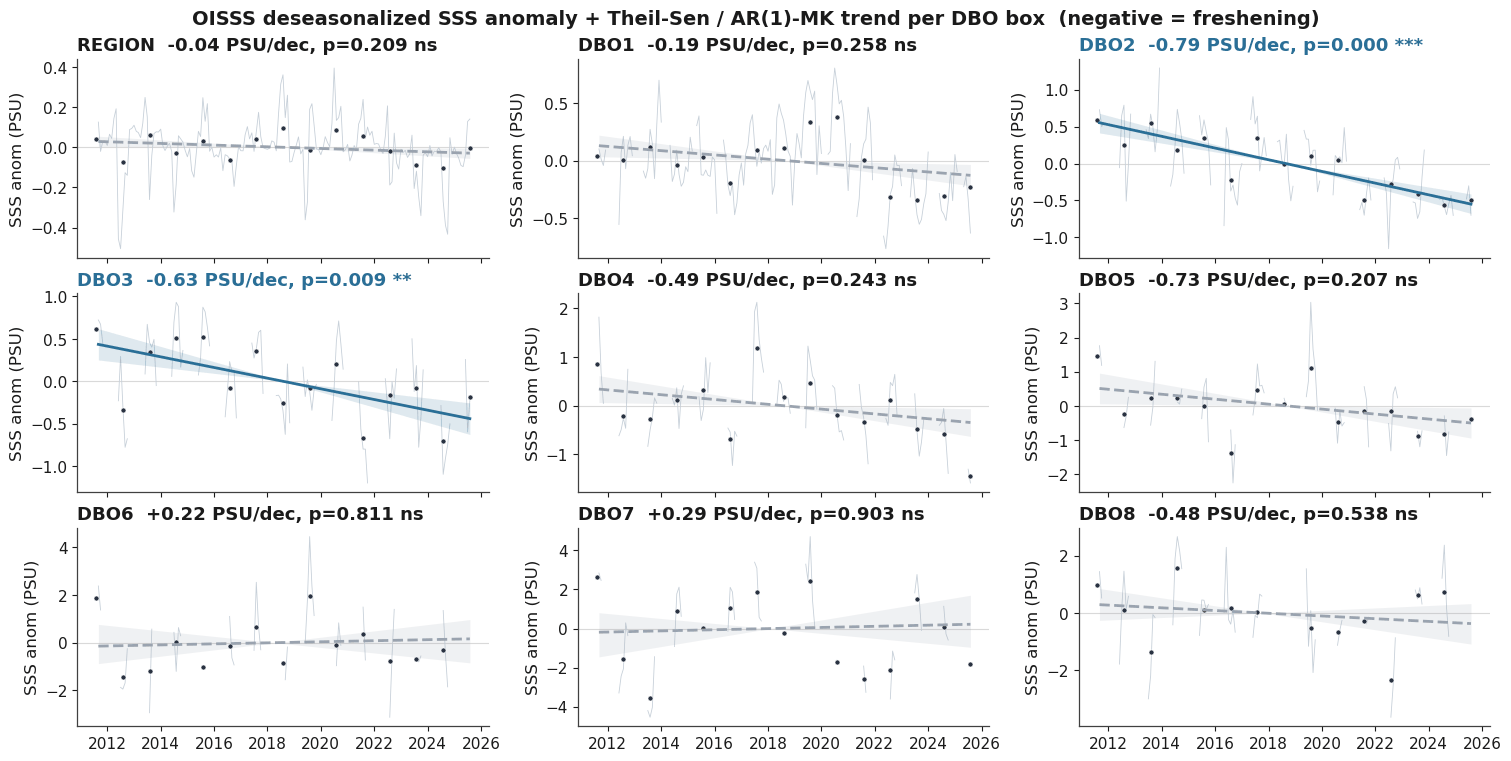

saved -> ~/outputs_longterm_oisss/oisss_sss_box_trends_theilsen.png


In [13]:
STYLE = {"font.family": "DejaVu Sans",
         "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
         "axes.spines.top": False, "axes.spines.right": False,
         "axes.edgecolor": "0.25", "axes.linewidth": 0.9,
         "axes.labelcolor": "0.1", "text.color": "0.1",
         "xtick.color": "0.1", "ytick.color": "0.1",
         "xtick.labelsize": 11, "ytick.labelsize": 11,
         "figure.facecolor": "white", "axes.facecolor": "white"}
RAW, DOT = "#C7D0D9", "#293241"
FRESH, SALT, NS = "#2A6F97", "#E76F51", "#9AA3AF"

names = list(series.keys())
ncol = 3; nrow = int(np.ceil(len(names) / ncol))
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.0 * ncol, 2.5 * nrow),
                             sharex=True, squeeze=False, constrained_layout=True)
    for ax, name in zip(axes.ravel(), names):
        anom = deseason(series[name])
        t = pd.to_datetime(anom["time"].values)
        y = np.asarray(anom.values, float)
        f = rows[name]
        ax.axhline(0, color="0.85", lw=0.8, zorder=0)
        ax.plot(t, y, lw=0.6, color=RAW, zorder=1)
        ser = pd.Series(y, index=t)
        ym_ = ser.groupby(ser.index.year).mean()
        ax.plot(pd.to_datetime([f"{yy}-08-01" for yy in ym_.index]), ym_.values,
                "o", ms=3.6, color=DOT, mec="white", mew=0.4, zorder=3)
        if np.isfinite(f["psu_per_decade"]):
            sig = np.isfinite(f["p_MK_AR1"]) and f["p_MK_AR1"] < 0.05
            c = (FRESH if f["psu_per_decade"] < 0 else SALT) if sig else NS
            dec = np.asarray(t.year + (t.month - 0.5) / 12.0, float)
            v = np.isfinite(y)
            x0 = dec[v].mean(); y0 = np.nanmean(y)
            yhat = (f["psu_per_decade"] / 10.0) * (dec - x0) + y0
            # --- 95% CI band: slopes at the Theil-Sen CI bounds, through the same anchor ---
            if np.isfinite(f["ci_lo"]) and np.isfinite(f["ci_hi"]):
                ylo = (f["ci_lo"] / 10.0) * (dec - x0) + y0
                yhi = (f["ci_hi"] / 10.0) * (dec - x0) + y0
                ax.fill_between(t, np.minimum(ylo, yhi), np.maximum(ylo, yhi),
                                color=c, alpha=0.15, lw=0, zorder=2)
            ax.plot(t, yhat, lw=2.0, color=c, ls="-" if sig else "--", zorder=4)
            ax.set_title(f"{name}  {f['psu_per_decade']:+.2f} PSU/dec, p={f['p_MK_AR1']:.3f} {f['sig']}",
                         loc="left", fontweight="bold", color=(c if sig else "0.1"))
        else:
            ax.set_title(f"{name} — insufficient data", loc="left")
        ax.set_ylabel("SSS anom (PSU)")
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    fig.suptitle("OISSS deseasonalized SSS anomaly + Theil-Sen / AR(1)-MK trend per DBO box"
                 "  (negative = freshening)", fontsize=14, fontweight="bold")
    fig.savefig(OUT_DIR / "oisss_sss_box_trends_theilsen.png", dpi=150, bbox_inches="tight")
    plt.show()
print("saved ->", OUT_DIR / "oisss_sss_box_trends_theilsen.png")

